# Analisis Graf: 5 Vertex (Berarah & Tidak Berarah)

Dokumen notebook ini berisi implementasi lengkap pembuatan **Graf Tidak Berarah (Undirected Graph)** dan **Graf Berarah (Directed Graph)** dengan 5 vertex (simpul) menggunakan pustaka `networkx` dan `matplotlib`.

Seluruh metrik dihitung sesuai instruksi tugas:
1. Visualisasi Graf (Berarah & Tidak Berarah)
2. Degree (Derajat) per Vertex (termasuk In-Degree & Out-Degree untuk graf berarah)
3. Rata-Rata Degree (Average Degree)
4. Distribusi Derajat (Degree Distribution)
5. Kepadatan Graf (Graph Density)
6. Koefisien Klasterisasi (Clustering Coefficient) per Vertex
7. Rata-Rata Lintasan Terpendek (Average Shortest Path Length)
8. Matriks Ketetanggaan (Adjacency Matrix)

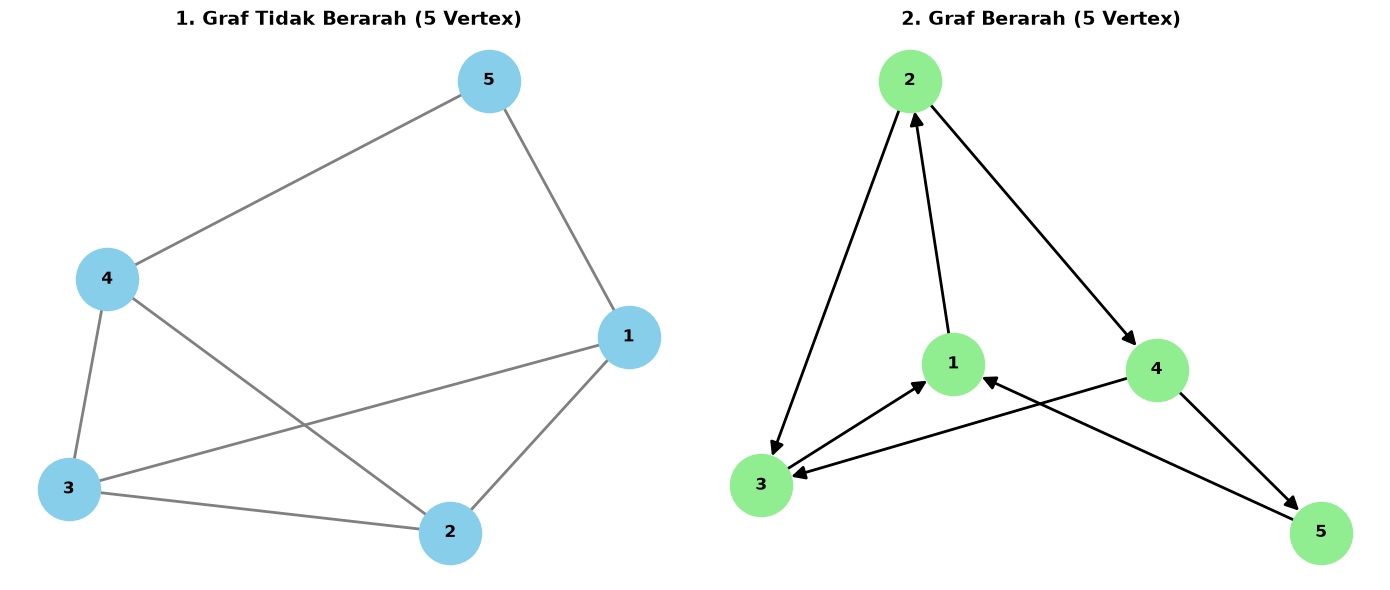

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import collections

# Inisialisasi Kanvas Visualisasi Side-by-Side
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

# 1. Graf Tidak Berarah (Undirected Graph - 5 Vertex)
G_undirected = nx.Graph()
nodes = [1, 2, 3, 4, 5]
edges_undirected = [(1, 2), (1, 3), (2, 3), (2, 4), (3, 4), (4, 5), (5, 1)]
G_undirected.add_nodes_from(nodes)
G_undirected.add_edges_from(edges_undirected)

pos_u = nx.spring_layout(G_undirected, seed=42)
axes[0].set_title("1. Graf Tidak Berarah (5 Vertex)", fontsize=14, fontweight='bold')
nx.draw(G_undirected, pos_u, ax=axes[0], 
        with_labels=True, node_color='skyblue', node_size=2000, 
        font_size=12, font_weight='bold', edge_color='gray', width=2)


# 2. Graf Berarah (Directed Graph - 5 Vertex)
# Dibuat Strongly Connected agar Average Shortest Path Length dapat dihitung
G_directed = nx.DiGraph()
edges_directed = [(1, 2), (2, 3), (3, 1), (2, 4), (4, 3), (4, 5), (5, 1)]
G_directed.add_nodes_from(nodes)
G_directed.add_edges_from(edges_directed)

pos_d = nx.spring_layout(G_directed, seed=42)
axes[1].set_title("2. Graf Berarah (5 Vertex)", fontsize=14, fontweight='bold')
nx.draw(G_directed, pos_d, ax=axes[1], 
        with_labels=True, node_color='lightgreen', node_size=2000, 
        font_size=12, font_weight='bold', edge_color='black', 
        arrows=True, arrowsize=20, width=2)

plt.tight_layout()
plt.show()

## 2. Analisis Metrik Graf Tidak Berarah (Undirected Graph)

Pada sel berikut dilakukan perhitungan seluruh metrik untuk graf tidak berarah:
- **Degree per Vertex**: Jumlah sisi terhubung pada tiap simpul.
- **Rata-Rata Degree**: Total derajat dibagi jumlah vertex ($N=5$).
- **Distribusi Derajat**: Frekuensi kemunculan nilai derajat dalam bentuk tabel dan diagram batang.
- **Graph Density**: Perbandingan sisi aktual dengan sisi maksimum yang mungkin ($\frac{2E}{N(N-1)}$).
- **Koefisien Klasterisasi per Vertex**: Mengukur kecenderungan tetangga simpul untuk saling terhubung membentuk segitiga.
- **Rata-Rata Lintasan Terpendek**: Rata-rata jarak terpendek antar seluruh pasangan vertex.
- **Adjacency Matrix**: Matriks biner $5 \times 5$ koneksi antar vertex.

     METRIK GRAF TIDAK BERARAH (UNDIRECTED GRAPH)  

1. Degree Masing-Masing Vertex:
   - Vertex 1: 3 sisi
   - Vertex 2: 3 sisi
   - Vertex 3: 3 sisi
   - Vertex 4: 3 sisi
   - Vertex 5: 2 sisi

2. Rata-Rata Degree: 2.80

3. Distribusi Derajat:
   - Degree 2: muncul pada 1 vertex
   - Degree 3: muncul pada 4 vertex


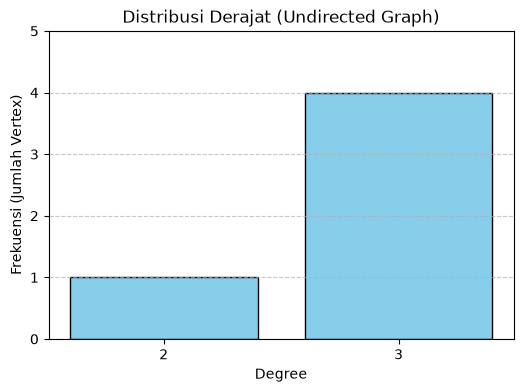

4. Density Graph: 0.7000

5. Koefisien Klasterisasi Masing-Masing Vertex:
   - Vertex 1: 0.3333
   - Vertex 2: 0.6667
   - Vertex 3: 0.6667
   - Vertex 4: 0.3333
   - Vertex 5: 0.0000

6. Rata-Rata Lintasan Terpendek (Avg Shortest Path Length): 1.3000

7. Matriks Ketetanggaan (Adjacency Matrix 5x5):
[[0 1 1 0 1]
 [1 0 1 1 0]
 [1 1 0 1 0]
 [0 1 1 0 1]
 [1 0 0 1 0]]


In [2]:
print("==================================================")
print("     METRIK GRAF TIDAK BERARAH (UNDIRECTED GRAPH)  ")
print("==================================================\n")

# A. Degree Masing-Masing Vertex
deg_u = dict(G_undirected.degree())
print("1. Degree Masing-Masing Vertex:")
for node, d in sorted(deg_u.items()):
    print(f"   - Vertex {node}: {d} sisi")

# B. Rata-Rata Degree
avg_deg_u = sum(deg_u.values()) / G_undirected.number_of_nodes()
print(f"\n2. Rata-Rata Degree: {avg_deg_u:.2f}")

# C. Distribusi Derajat (Text & Plot)
deg_seq_u = [d for n, d in G_undirected.degree()]
deg_count_u = collections.Counter(deg_seq_u)
print("\n3. Distribusi Derajat:")
for d_val, count in sorted(deg_count_u.items()):
    print(f"   - Degree {d_val}: muncul pada {count} vertex")

plt.figure(figsize=(6, 4))
plt.bar(list(deg_count_u.keys()), list(deg_count_u.values()), color='skyblue', edgecolor='black')
plt.title("Distribusi Derajat (Undirected Graph)")
plt.xlabel("Degree")
plt.ylabel("Frekuensi (Jumlah Vertex)")
plt.xticks(list(deg_count_u.keys()))
plt.yticks(range(0, max(deg_count_u.values()) + 2))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# D. Density Graph
density_u = nx.density(G_undirected)
print(f"4. Density Graph: {density_u:.4f}")

# E. Koefisien Klasterisasi Masing-Masing Vertex
cluster_u = nx.clustering(G_undirected)
print("\n5. Koefisien Klasterisasi Masing-Masing Vertex:")
for node, c in sorted(cluster_u.items()):
    print(f"   - Vertex {node}: {c:.4f}")

# F. Rata-Rata Lintasan Terpendek (Average Shortest Path Length)
avg_sp_u = nx.average_shortest_path_length(G_undirected)
print(f"\n6. Rata-Rata Lintasan Terpendek (Avg Shortest Path Length): {avg_sp_u:.4f}")

# G. Matriks Ketetanggaan (Adjacency Matrix)
adj_u = nx.adjacency_matrix(G_undirected).todense()
print("\n7. Matriks Ketetanggaan (Adjacency Matrix 5x5):")
print(adj_u)

## 3. Analisis Metrik Graf Berarah (Directed Graph / Digraph)

Pada sel berikut dilakukan perhitungan seluruh metrik untuk graf berarah:
- **Degree per Vertex**: Membedakan **In-Degree** (sisi masuk), **Out-Degree** (sisi keluar), dan **Total Degree**.
- **Rata-Rata Degree**: Rata-rata In-Degree, Out-Degree, dan Total Degree.
- **Distribusi Derajat**: Frekuensi total derajat pada graf berarah.
- **Graph Density**: Perbandingan sisi berarah aktual dengan kapasitas maksimum ($N(N-1)$).
- **Koefisien Klasterisasi per Vertex**: Mengukur kecenderungan hubungan bertetangga pada graf berarah (directed clustering).
- **Rata-Rata Lintasan Terpendek**: Rata-rata lintasan terpendek dengan memperhatikan arah panah.
- **Adjacency Matrix**: Matriks $5 \times 5$ di mana entri $(i, j) = 1$ menunjukkan adanya panah dari vertex $i$ ke vertex $j$.

       METRIK GRAF BERARAH (DIRECTED GRAPH)       

1. Degree Masing-Masing Vertex:
   - Vertex 1: Total Degree = 3 | In-Degree = 2 | Out-Degree = 1
   - Vertex 2: Total Degree = 3 | In-Degree = 1 | Out-Degree = 2
   - Vertex 3: Total Degree = 3 | In-Degree = 2 | Out-Degree = 1
   - Vertex 4: Total Degree = 3 | In-Degree = 1 | Out-Degree = 2
   - Vertex 5: Total Degree = 2 | In-Degree = 1 | Out-Degree = 1

2. Rata-Rata Degree:
   - Rata-Rata Total Degree : 2.80
   - Rata-Rata In-Degree   : 1.40
   - Rata-Rata Out-Degree  : 1.40

3. Distribusi Total Degree:
   - Degree 2: muncul pada 1 vertex
   - Degree 3: muncul pada 4 vertex


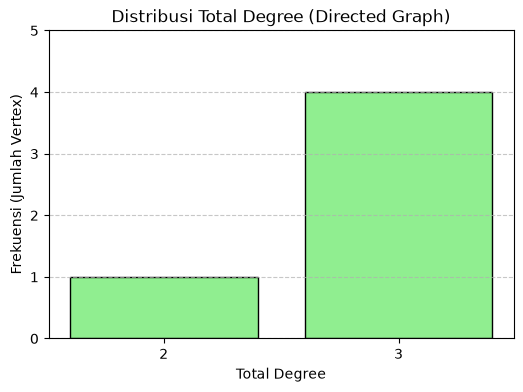

4. Density Graph: 0.3500

5. Koefisien Klasterisasi Masing-Masing Vertex:
   - Vertex 1: 0.1667
   - Vertex 2: 0.3333
   - Vertex 3: 0.3333
   - Vertex 4: 0.1667
   - Vertex 5: 0.0000

6. Rata-Rata Lintasan Terpendek (Avg Shortest Path Length): 2.0000

7. Matriks Ketetanggaan (Adjacency Matrix 5x5):
[[0 1 0 0 0]
 [0 0 1 1 0]
 [1 0 0 0 0]
 [0 0 1 0 1]
 [1 0 0 0 0]]


In [3]:
print("==================================================")
print("       METRIK GRAF BERARAH (DIRECTED GRAPH)       ")
print("==================================================\n")

# A. Degree Masing-Masing Vertex (In, Out, Total)
in_deg_d = dict(G_directed.in_degree())
out_deg_d = dict(G_directed.out_degree())
tot_deg_d = dict(G_directed.degree())

print("1. Degree Masing-Masing Vertex:")
for node in sorted(G_directed.nodes()):
    print(f"   - Vertex {node}: Total Degree = {tot_deg_d[node]} | In-Degree = {in_deg_d[node]} | Out-Degree = {out_deg_d[node]}")

# B. Rata-Rata Degree
avg_tot_deg_d = sum(tot_deg_d.values()) / G_directed.number_of_nodes()
avg_in_deg_d = sum(in_deg_d.values()) / G_directed.number_of_nodes()
avg_out_deg_d = sum(out_deg_d.values()) / G_directed.number_of_nodes()
print(f"\n2. Rata-Rata Degree:")
print(f"   - Rata-Rata Total Degree : {avg_tot_deg_d:.2f}")
print(f"   - Rata-Rata In-Degree   : {avg_in_deg_d:.2f}")
print(f"   - Rata-Rata Out-Degree  : {avg_out_deg_d:.2f}")

# C. Distribusi Derajat (Total Degree)
deg_seq_d = [d for n, d in G_directed.degree()]
deg_count_d = collections.Counter(deg_seq_d)
print("\n3. Distribusi Total Degree:")
for d_val, count in sorted(deg_count_d.items()):
    print(f"   - Degree {d_val}: muncul pada {count} vertex")

plt.figure(figsize=(6, 4))
plt.bar(list(deg_count_d.keys()), list(deg_count_d.values()), color='lightgreen', edgecolor='black')
plt.title("Distribusi Total Degree (Directed Graph)")
plt.xlabel("Total Degree")
plt.ylabel("Frekuensi (Jumlah Vertex)")
plt.xticks(list(deg_count_d.keys()))
plt.yticks(range(0, max(deg_count_d.values()) + 2))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# D. Density Graph
density_d = nx.density(G_directed)
print(f"4. Density Graph: {density_d:.4f}")

# E. Koefisien Klasterisasi Masing-Masing Vertex
cluster_d = nx.clustering(G_directed)
print("\n5. Koefisien Klasterisasi Masing-Masing Vertex:")
for node, c in sorted(cluster_d.items()):
    print(f"   - Vertex {node}: {c:.4f}")

# F. Rata-Rata Lintasan Terpendek (Average Shortest Path Length)
avg_sp_d = nx.average_shortest_path_length(G_directed)
print(f"\n6. Rata-Rata Lintasan Terpendek (Avg Shortest Path Length): {avg_sp_d:.4f}")

# G. Matriks Ketetanggaan (Adjacency Matrix)
adj_d = nx.adjacency_matrix(G_directed).todense()
print("\n7. Matriks Ketetanggaan (Adjacency Matrix 5x5):")
print(adj_d)

## 4. Kesimpulan dan Interpretasi Metrik

Berdasarkan hasil komputasi metrik pada graf 5 vertex di atas (baik yang tidak berarah maupun berarah), berikut adalah interpretasi dari angka-angka yang dihasilkan:

### A. Karakteristik Graf Tidak Berarah (Undirected Graph)
1. **Degree & Distribusi:** Kita dapat melihat vertex mana yang bertindak sebagai *hub* (pusat koneksi). Vertex dengan *degree* tertinggi adalah titik yang paling krusial dalam graf ini.
2. **Kepadatan (Density):** Nilai *density* menunjukkan seberapa terhubung jaringan ini dibandingkan dengan potensi maksimalnya. Semakin mendekati 1, semakin padat graf tersebut (*dense*), dan jika mendekati 0 disebut graf renggang (*sparse*).
3. **Koefisien Klasterisasi:** Menunjukkan seberapa kuat komunitas yang terbentuk. Jika nilainya 0 pada suatu vertex, berarti tidak ada satupun tetangganya yang saling terhubung satu sama lain.
4. **Rata-Rata Lintasan Terpendek:** Menunjukkan rata-rata "langkah" atau *hops* yang dibutuhkan untuk berpindah dari satu vertex ke vertex lain. Angka yang kecil menandakan komunikasi/aliran informasi dalam jaringan ini sangat cepat (efek *small-world*).

### B. Karakteristik Graf Berarah (Directed Graph)
1. **In-Degree dan Out-Degree:** 
   - Vertex dengan **In-Degree** tinggi mengindikasikan popularitas atau tujuan aliran informasi (sebagai *sink* atau penerima).
   - Vertex dengan **Out-Degree** tinggi menunjukkan sumber pengaruh atau penyebar informasi utama (sebagai *source*).
2. **Adjacency Matrix (Matriks Ketetanggaan):** Berbeda dengan graf tidak berarah yang matriksnya simetris (cermin di garis diagonal), matriks pada graf berarah cenderung **tidak simetris** karena koneksi $A \rightarrow B$ tidak menjamin adanya koneksi $B \rightarrow A$.
3. **Rata-Rata Lintasan Terpendek:** Terkadang jalurnya bisa lebih panjang dari graf tidak berarah, karena pergerakan dibatasi secara ketat oleh arah panah.